# Qwen3-4B PPO — method comparison

Compares **vanilla**, **maxmin**, and **pcgrad** PPO policies trained on the **Qwen3-4B** backbone,
evaluated on the IMDB test prompts and scored with the gold DistilBERT sentiment model.

**Config available:** `prop=0.2, alpha=1.0, seed=42, mean_kl0.1` (one eval per method).

## How to read this fairly

At `alpha=1.0` the oracle group utilities reduce to:
- **minority score = conciseness** $=1-\ell$ (the minority prefers short responses)
- **majority score = positiveness** $=p$ (the majority prefers positive sentiment)

**Which metric answers the fairness question?**
- ✅ **Worst-off group** = `min(mean minority, mean majority)` — this is the *egalitarian* welfare MaxMin/PCGrad
  optimize. **This is the headline fairness metric.**
- ✅ **Fairness gap** = majority − minority (closer to 0 = fairer).
- ⚠️ **"Overall"** = `p·min + (1-p)·maj` is *utilitarian* welfare. With a 20% minority it is **80% weighted on the
  majority objective**, so the positiveness-maximizer (vanilla) wins it *by construction* — it does **not** measure
  fairness. Don't use it as the headline.

## ⚠️ Important caveat for THIS eval

This eval was generated with `max_new_tokens=128`, and **all methods hit that cap** (see the length diagnostic
below). With almost no length variation, **conciseness carries little signal**, so the **minority / worst-group /
gap numbers are largely artifacts of the `DIVISOR` normalization** (the diagnostic shows how they flip with DIVISOR).
Only **positiveness** is robust here. To get a trustworthy conciseness signal, re-generate the eval with a larger
`max_new_tokens` (≈256–500, closer to the len512 training reward).

In [1]:
import sys, os, re
ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.abspath(os.path.join(ROOT, ".."))
sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# Self-contained loader (mirrors src.helper.imdb_utils.load_ppo_eval, without the
# transformers import) so this notebook only needs datasets + pandas + matplotlib.
def load_ppo_eval(repo_id, split="train"):
    try:
        data = load_dataset(repo_id)
    except Exception:
        data = load_dataset("parquet", data_files=f"hf://datasets/{repo_id}/data/train-*.parquet")
    if hasattr(data, "keys"):
        return data[split if split in data else list(data.keys())[0]]
    return data

sns.set_theme(style="whitegrid", context="talk", palette="colorblind", font_scale=0.85)
METHOD_COLORS = {
    "vanilla": sns.color_palette("colorblind")[0],
    "maxmin":  sns.color_palette("colorblind")[1],
    "pcgrad":  sns.color_palette("colorblind")[2],
}
METHOD_LABELS  = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad"}
METHOD_MARKERS = {"vanilla": "o", "maxmin": "s", "pcgrad": "^"}

# ---------------------------------------------------------------- configuration
USER_ID    = "mxcui"
METHODS    = ["vanilla", "maxmin", "pcgrad"]
PROPORTION = 0.2
ALPHA      = 1.0
SEED       = 42
# Qwen eval repos are named: {method}-imdb-ppo-eval-prop{p}-alpha{a}-seed{s}-mean_kl0.1-Qwen-Qwen3-4B-Base
TAIL       = "mean_kl0.1-Qwen-Qwen3-4B-Base"
DIVISOR    = 256   # normalized_length = clip(length/DIVISOR, 0, 1); conciseness = 1 - it

# ------------------------------------------------------ oracle score definitions
def oracle_minority(pos, nl, alpha):
    return (1 - nl) * alpha + (1 - alpha) * pos

def oracle_majority(pos, nl, alpha):
    return (1 - nl) * (1 - alpha) + alpha * pos

def eval_repo(method):
    return f"{USER_ID}/{method}-imdb-ppo-eval-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}-{TAIL}"

for m in METHODS:
    print(f"{m:8s} -> {eval_repo(m)}")

/root/miniconda3/envs/fairness-rlhf/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


vanilla  -> mxcui/vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed42-mean_kl0.1-Qwen-Qwen3-4B-Base
maxmin   -> mxcui/maxmin-imdb-ppo-eval-prop0.2-alpha1.0-seed42-mean_kl0.1-Qwen-Qwen3-4B-Base
pcgrad   -> mxcui/pcgrad-imdb-ppo-eval-prop0.2-alpha1.0-seed42-mean_kl0.1-Qwen-Qwen3-4B-Base


## 1. Load and score the evaluation datasets


In [2]:
# `positiveness` may be stored as a scalar P(pos) or as a raw 2-logit [neg, pos] array.
def to_prob(v):
    a = np.asarray(v, dtype=float)
    if a.ndim == 0:      return float(a)
    if a.size == 1:      return float(a.reshape(-1)[0])
    if a.size == 2:                       # [neg_logit, pos_logit] -> softmax pos
        e = np.exp(a - a.max()); return float((e / e.sum())[1])
    return float(a.reshape(-1)[-1])

results = {}   # method -> scored DataFrame
for method in METHODS:
    repo = eval_repo(method)
    try:
        df = load_ppo_eval(repo).to_pandas()
    except Exception as e:
        print(f"[skip] {method}: could not load {repo}: {e}")
        continue
    if "positiveness" not in df.columns or "length" not in df.columns:
        print(f"[skip] {method}: missing positiveness/length columns")
        continue
    df["positiveness"]     = df["positiveness"].map(to_prob)
    df["normalized_length"] = np.clip(df["length"].astype(float) / DIVISOR, 0, 1)
    df["conciseness"]       = 1 - df["normalized_length"]
    df["minority_score"]    = oracle_minority(df["positiveness"], df["normalized_length"], ALPHA)
    df["majority_score"]    = oracle_majority(df["positiveness"], df["normalized_length"], ALPHA)
    df["overall_performance"] = PROPORTION * df["minority_score"] + (1 - PROPORTION) * df["majority_score"]
    df["score_gap"]         = df["majority_score"] - df["minority_score"]
    results[method] = df
    print(f"[ok]   {method}: {len(df):>6d} completions loaded")

print("\nLoaded methods:", list(results.keys()))

[ok]   vanilla:  24872 completions loaded


[ok]   maxmin:  24872 completions loaded


[ok]   pcgrad:  24872 completions loaded

Loaded methods: ['vanilla', 'maxmin', 'pcgrad']


In [3]:
# === Robustness diagnostic: is the conciseness signal real in THIS eval? =========
# `length` is in DistilBERT tokens; generation was capped at max_new_tokens=128
# (Qwen tokens). If responses all sit at the cap, conciseness has no variation and
# the minority / worst-group / gap numbers become artifacts of DIVISOR.
methods_have = [m for m in METHODS if m in results]

print("Response length (DistilBERT tokens):")
print(f"{'method':8s} {'mean':>7s} {'median':>7s} {'std':>6s} {'CV':>6s}")
for m in methods_have:
    L = results[m]["length"].astype(float).values
    cv = L.std() / L.mean() if L.mean() else float("nan")
    print(f"{m:8s} {L.mean():7.1f} {np.median(L):7.0f} {L.std():6.1f} {cv:6.2f}")

if all(results[m]["length"].astype(float).std() < 30 for m in methods_have):
    print("\n[WARNING] Length is nearly constant across responses (pinned near the "
          "generation cap).\n          -> Conciseness has little signal; treat "
          "minority / worst_group / gap as UNRELIABLE.\n          Re-generate the eval "
          "with a larger max_new_tokens (256-500) to fix this.")

print("\nDIVISOR sensitivity of the fairness metrics (why the conclusion is fragile):")
hdr = "  ".join(f"{METHOD_LABELS[m]:>13s}" for m in methods_have)
print(f"{'DIVISOR':>7s} |  {hdr}   [worst / gap]")
for DIV in (128, 192, 256, 384, 512):
    cells = []
    for m in methods_have:
        L = results[m]["length"].astype(float).values
        conc = (1 - np.clip(L / DIV, 0, 1)).mean()
        pos = results[m]["positiveness"].mean()
        cells.append(f"{min(conc, pos):5.2f}/{pos - conc:5.2f}")
    print(f"{DIV:>7d} |  " + "  ".join(f"{c:>13s}" for c in cells))
print("\n(Only `positiveness` is DIVISOR-independent and therefore trustworthy here.)")

Response length (DistilBERT tokens):
method      mean  median    std     CV
vanilla    129.7     130    3.9   0.03
maxmin     140.4     144   14.5   0.10
pcgrad     127.9     133   19.7   0.15

[WARNING] Length is nearly constant across responses (pinned near the generation cap).
          -> Conciseness has little signal; treat minority / worst_group / gap as UNRELIABLE.
          Re-generate the eval with a larger max_new_tokens (256-500) to fix this.

DIVISOR sensitivity of the fairness metrics (why the conclusion is fragile):
DIVISOR |        Vanilla         MaxMin         PCGrad   [worst / gap]
    128 |     0.00/ 0.99     0.01/ 0.68     0.05/ 0.65
    192 |     0.32/ 0.67     0.27/ 0.43     0.33/ 0.37
    256 |     0.49/ 0.50     0.45/ 0.24     0.50/ 0.20
    384 |     0.66/ 0.33     0.63/ 0.06     0.67/ 0.04
    512 |     0.75/ 0.25     0.70/-0.03     0.71/-0.05

(Only `positiveness` is DIVISOR-independent and therefore trustworthy here.)


## 2. Summary table

Per-method means (± std). **`worst_group` = min(mean minority, mean majority) is the fairness headline**
(egalitarian welfare — MaxMin/PCGrad aim to raise it). `score_gap` = majority − minority (→0 is fairer).
`overall_performance` is utilitarian (`p·min + (1-p)·maj`, 80% majority here) and is shown only for context —
it favors the positiveness-maximizer by construction, so it is **not** the fairness metric.

⚠️ Per the diagnostic above, `conciseness` (and therefore `minority_score`, `worst_group`, `score_gap`) is
unreliable in this 128-token-capped eval; `positiveness`/`majority_score` are the only robust columns.

In [4]:
METRICS = ["positiveness", "conciseness", "minority_score", "majority_score",
           "overall_performance", "score_gap"]
rows = []
for method in METHODS:
    if method not in results: continue
    df = results[method]
    row = {"method": METHOD_LABELS[method]}
    for m in METRICS:
        row[m] = df[m].mean()
        row[m + "_std"] = df[m].std()
    row["worst_group"] = min(df["minority_score"].mean(), df["majority_score"].mean())
    row["n"] = len(df)
    rows.append(row)

summary = pd.DataFrame(rows).set_index("method")
display_cols = ["positiveness", "conciseness", "minority_score", "majority_score",
                "worst_group", "overall_performance", "score_gap", "n"]
summary_display = summary[display_cols].round(4)
summary_display

,positiveness,conciseness,minority_score,majority_score,worst_group,overall_performance,score_gap,n
method,,,,,,,,
Vanilla,0.9948,0.4935,0.4935,0.9948,0.4935,0.8946,0.5013,24872
MaxMin,0.6956,0.4515,0.4515,0.6956,0.4515,0.6468,0.2442,24872
PCGrad,0.7050,0.5004,0.5004,0.7050,0.5004,0.6641,0.2046,24872


## 3. Fairness view — minority vs majority group score

The core plot. Grouped bars show each group's mean oracle utility per method; the dashed line marks
each method's **worst-off group** (what MaxMin optimizes). A fair method lifts the lower bar and
shrinks the gap between the two.


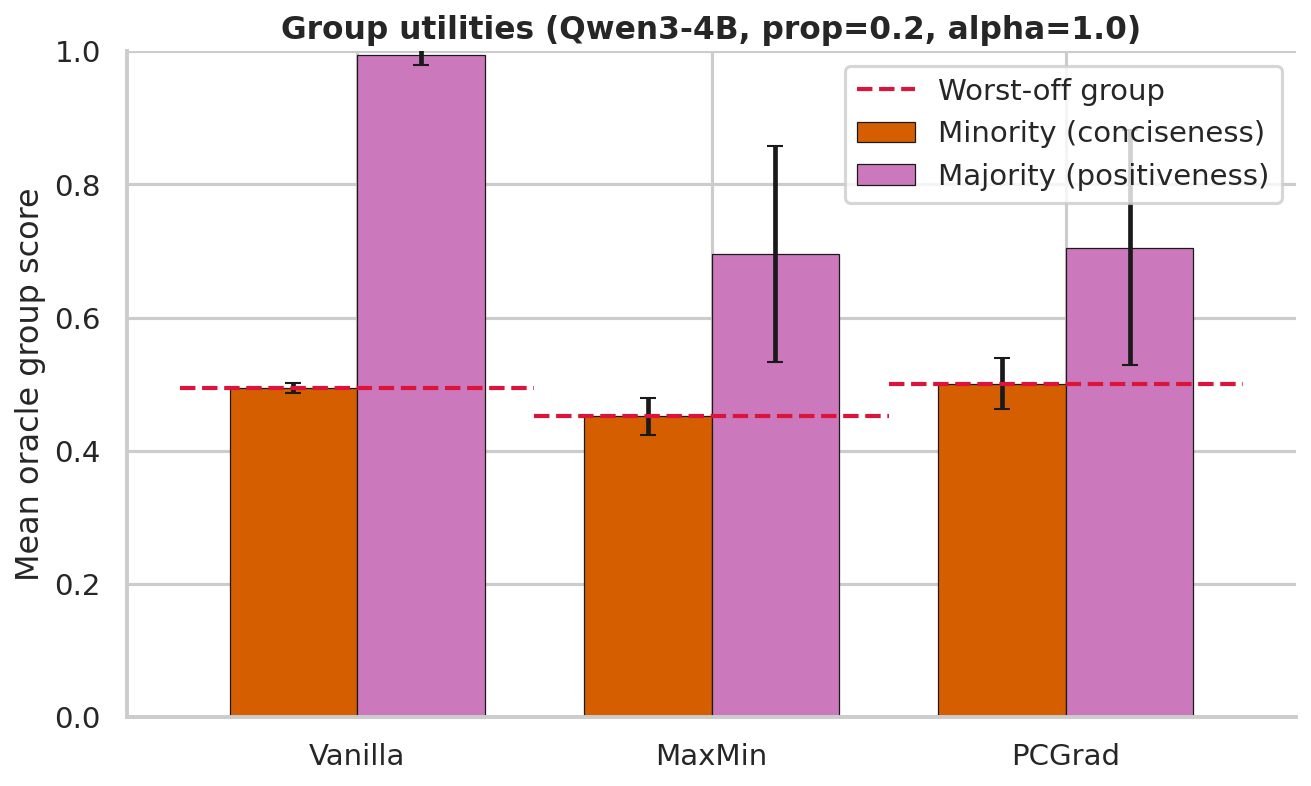

In [5]:
methods_have = [m for m in METHODS if m in results]
x = np.arange(len(methods_have)); w = 0.36
min_   = [results[m]["minority_score"].mean() for m in methods_have]
maj    = [results[m]["majority_score"].mean() for m in methods_have]
min_e  = [results[m]["minority_score"].std()  for m in methods_have]
maj_e  = [results[m]["majority_score"].std()  for m in methods_have]

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
b1 = ax.bar(x - w/2, min_, w, yerr=0.5*np.array(min_e), capsize=4,
            label="Minority (conciseness)", color=sns.color_palette("colorblind")[3], edgecolor="k", linewidth=0.6)
b2 = ax.bar(x + w/2, maj,  w, yerr=0.5*np.array(maj_e), capsize=4,
            label="Majority (positiveness)", color=sns.color_palette("colorblind")[4], edgecolor="k", linewidth=0.6)
for xi, m in zip(x, methods_have):
    wg = min(results[m]["minority_score"].mean(), results[m]["majority_score"].mean())
    ax.hlines(wg, xi - 0.5, xi + 0.5, color="crimson", linestyle="--", linewidth=2, zorder=5)
ax.plot([], [], color="crimson", linestyle="--", linewidth=2, label="Worst-off group")
ax.set_xticks(x); ax.set_xticklabels([METHOD_LABELS[m] for m in methods_have])
ax.set_ylabel("Mean oracle group score"); ax.set_ylim(0, 1)
ax.set_title(f"Group utilities (Qwen3-4B, prop={PROPORTION}, alpha={ALPHA})", fontweight="semibold", fontsize=15)
ax.legend(frameon=True); sns.despine(ax=ax)
plt.tight_layout(); plt.savefig("qwen_group_scores.pdf", bbox_inches="tight", dpi=300); plt.show()

## 4. Underlying attributes — positiveness & conciseness


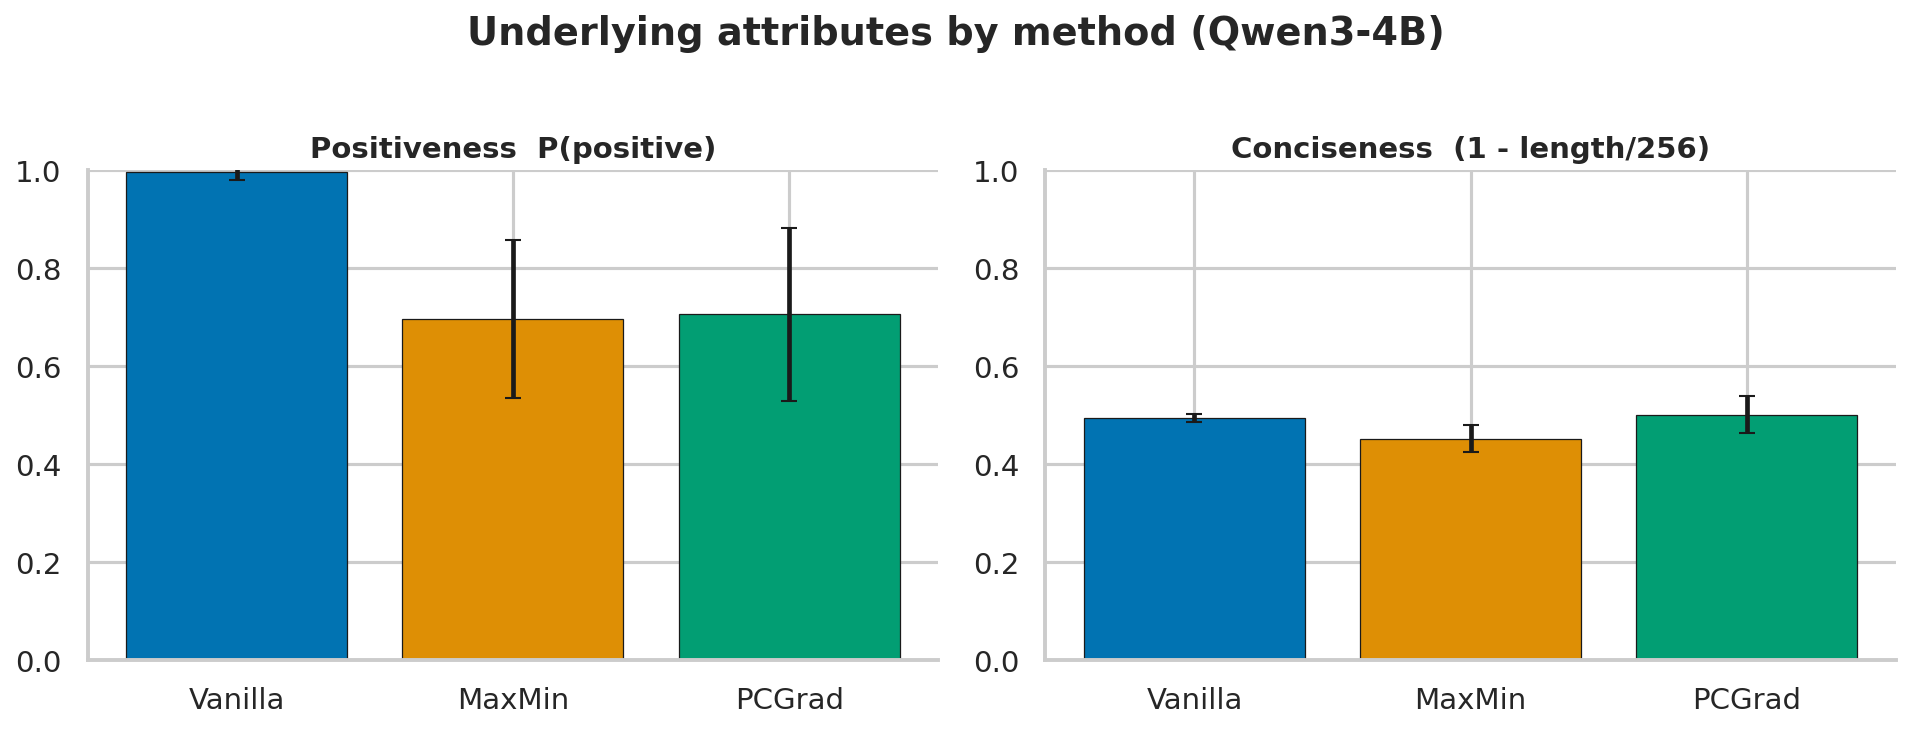

In [6]:
methods_have = [m for m in METHODS if m in results]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
for ax, metric, title in [(axes[0], "positiveness", "Positiveness  P(positive)"),
                          (axes[1], "conciseness", "Conciseness  (1 - length/%d)" % DIVISOR)]:
    means = [results[m][metric].mean() for m in methods_have]
    errs  = [0.5*results[m][metric].std() for m in methods_have]
    ax.bar([METHOD_LABELS[m] for m in methods_have], means, yerr=errs, capsize=4,
           color=[METHOD_COLORS[m] for m in methods_have], edgecolor="k", linewidth=0.6)
    ax.set_title(title, fontweight="semibold", fontsize=14); ax.set_ylim(0, 1); sns.despine(ax=ax)
fig.suptitle("Underlying attributes by method (Qwen3-4B)", y=1.02, fontweight="semibold")
plt.tight_layout(); plt.savefig("qwen_attributes.pdf", bbox_inches="tight", dpi=300); plt.show()

## 5. Utilitarian "overall" & fairness gap  *(context only)*

**Left — utilitarian welfare** `p·min + (1-p)·maj`. With p=0.2 this is 80% majority, so the
positiveness-maximizer (**vanilla**) wins it *by construction*. This is **not** a fairness result — it is the
standard fairness/efficiency tension: vanilla maximizes total welfare while being the least fair. Do not headline it.

**Right — fairness gap** (majority − minority), closer to 0 = fairer. (Still DIVISOR-sensitive here; see diagnostic.)

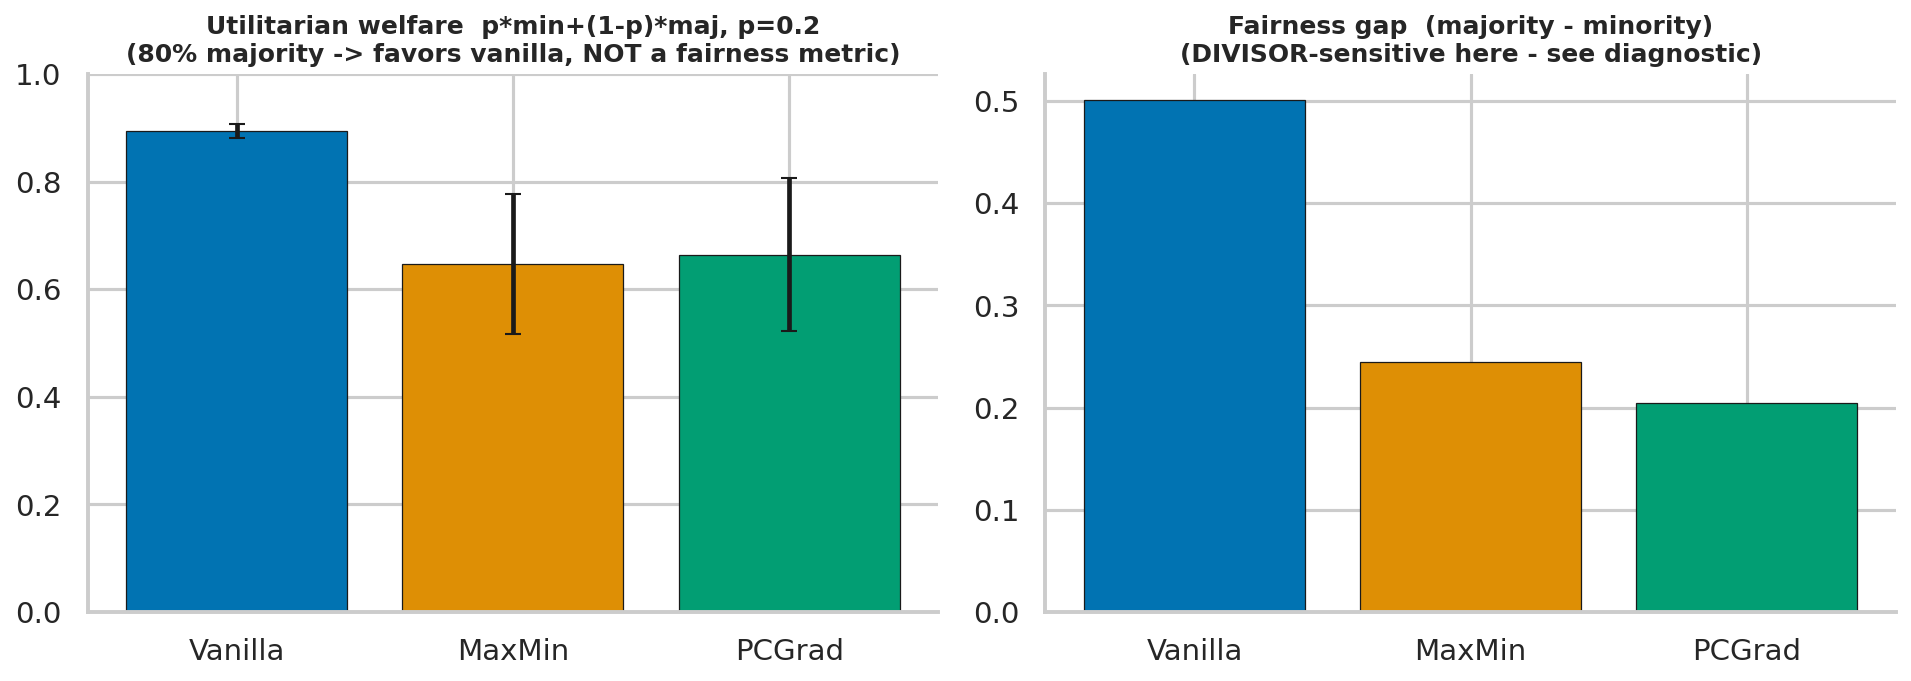

In [7]:
methods_have = [m for m in METHODS if m in results]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
# overall = p*min + (1-p)*maj  -- UTILITARIAN, majority-weighted (context only)
ov = [results[m]["overall_performance"].mean() for m in methods_have]
ov_e = [0.5*results[m]["overall_performance"].std() for m in methods_have]
axes[0].bar([METHOD_LABELS[m] for m in methods_have], ov, yerr=ov_e, capsize=4,
            color=[METHOD_COLORS[m] for m in methods_have], edgecolor="k", linewidth=0.6)
axes[0].set_title(f"Utilitarian welfare  p*min+(1-p)*maj, p={PROPORTION}\n(80% majority -> favors vanilla, NOT a fairness metric)",
                  fontweight="semibold", fontsize=12)
axes[0].set_ylim(0, 1); sns.despine(ax=axes[0])
# gap = maj - min  (closer to 0 = fairer)
gap = [results[m]["majority_score"].mean() - results[m]["minority_score"].mean() for m in methods_have]
axes[1].axhline(0, color="gray", ls=":", lw=1.2)
axes[1].bar([METHOD_LABELS[m] for m in methods_have], gap,
            color=[METHOD_COLORS[m] for m in methods_have], edgecolor="k", linewidth=0.6)
axes[1].set_title("Fairness gap  (majority - minority)\n(DIVISOR-sensitive here - see diagnostic)",
                  fontweight="semibold", fontsize=12)
sns.despine(ax=axes[1])
plt.tight_layout(); plt.savefig("qwen_overall_gap.pdf", bbox_inches="tight", dpi=300); plt.show()

## 6. Distributions of positiveness and length


/tmp/ipykernel_558594/4028055675.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=long, x="method", y="positiveness", order=order, palette=pal, ax=axes[0], cut=0, inner="quartile")
/tmp/ipykernel_558594/4028055675.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=long, x="method", y="length", order=order, palette=pal, ax=axes[1], cut=0, inner="quartile")


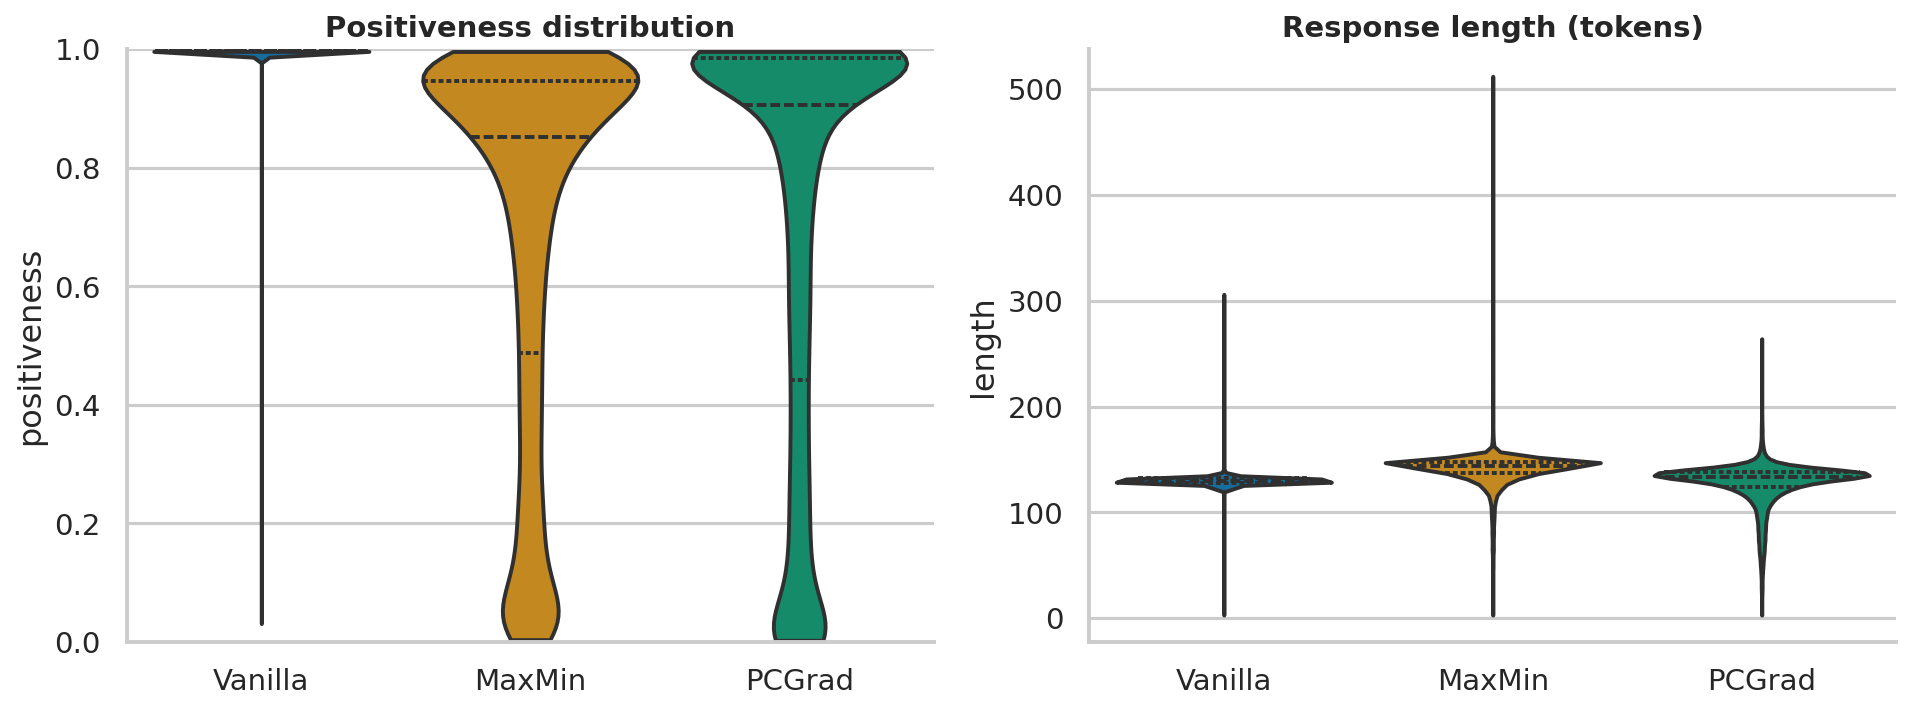

In [8]:
methods_have = [m for m in METHODS if m in results]
long = pd.concat([results[m].assign(method=METHOD_LABELS[m]) for m in methods_have], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
order = [METHOD_LABELS[m] for m in methods_have]
pal = {METHOD_LABELS[m]: METHOD_COLORS[m] for m in methods_have}
sns.violinplot(data=long, x="method", y="positiveness", order=order, palette=pal, ax=axes[0], cut=0, inner="quartile")
axes[0].set_title("Positiveness distribution", fontweight="semibold", fontsize=14); axes[0].set_ylim(0, 1)
sns.violinplot(data=long, x="method", y="length", order=order, palette=pal, ax=axes[1], cut=0, inner="quartile")
axes[1].set_title("Response length (tokens)", fontweight="semibold", fontsize=14)
for ax in axes: ax.set_xlabel(""); sns.despine(ax=ax)
plt.tight_layout(); plt.savefig("qwen_distributions.pdf", bbox_inches="tight", dpi=300); plt.show()

## 7. Takeaways

**Robust conclusion (positiveness):** Vanilla is almost maximally positive (~0.99); MaxMin (~0.70) and PCGrad
(~0.71) trade extreme positivity away. So the fairness methods clearly move mass off the majority-only objective.

**Do NOT conclude from "overall":** vanilla's higher `overall` is *expected* — utilitarian welfare with a 20%
minority is 80% majority-weighted, so the positiveness-maximizer wins it by construction. That is the
efficiency/fairness tension, not evidence against fairness methods.

**Cannot yet validate the minority (conciseness) side:** this eval capped generation at `max_new_tokens=128` and
every method pinned to the cap (see diagnostic — length std is tiny). Conciseness has no variation, so
`minority_score` / `worst_group` / `score_gap` swing with `DIVISOR` (they even change sign between DIVISOR 128 and
512). **Treat those numbers as unreliable.**

**To make a real fairness claim, re-run the eval** with `max_new_tokens ≈ 256` (or 500, matching the len512
training reward) so responses can actually be short, then re-run this notebook. The bars/table become meaningful
and DIVISOR-robust.

*Also:* single config (prop=0.2, alpha=1.0, seed=42). For paper-grade claims, extend Qwen to the
proportion/alpha/seed sweep like `analyze_ppo_by_prop.ipynb` does for GPT-2.

In [9]:
# Save the summary table next to the figures
summary_display.to_csv("qwen_method_comparison_summary.csv")
print("Saved qwen_method_comparison_summary.csv")
summary_display

Saved qwen_method_comparison_summary.csv


,positiveness,conciseness,minority_score,majority_score,worst_group,overall_performance,score_gap,n
method,,,,,,,,
Vanilla,0.9948,0.4935,0.4935,0.9948,0.4935,0.8946,0.5013,24872
MaxMin,0.6956,0.4515,0.4515,0.6956,0.4515,0.6468,0.2442,24872
PCGrad,0.7050,0.5004,0.5004,0.7050,0.5004,0.6641,0.2046,24872
